In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

In [3]:
# ---------------- scikit-learn ----------------
from sklearn.experimental import enable_halving_search_cv 
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, HalvingRandomSearchCV
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (
    f1_score, accuracy_score, balanced_accuracy_score,
    classification_report, confusion_matrix, average_precision_score
)
from sklearn.utils.validation import check_is_fitted


In [4]:
# ---------------- Optuna (TPE + ASHA) ----------------
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import SuccessiveHalvingPruner

/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
# ---------------- Repro / Display ----------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [6]:
# ---------------- Config ----------------
CSV_PATH   = r"/mnt/c/Users/Ishara/Documents/MPhil/Dataset/Final dataset/without timing/full sim results.csv"
TARGET_COL = "isUnderAttack"   # integer labels {0,1,2,3}

df = pd.read_csv(CSV_PATH)
X = df.drop(columns=[TARGET_COL]).values
y = df[TARGET_COL].values

print(f"[INFO] Loaded {X.shape[0]:,} rows × {X.shape[1]} features")
classes, counts = np.unique(y, return_counts=True)
print("[INFO] Class counts:", dict(zip(classes, counts)))

# 75:25 stratified split 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

# 10-fold stratified CV 
N_SPLITS = 10
skf10 = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

[INFO] Loaded 58,025 rows × 10 features
[INFO] Class counts: {0: 25773, 1: 12981, 2: 12959, 3: 6312}


In [7]:
# ================================================================
# 1) HELPERS: pipeline factory + metrics
# ================================================================
def make_svc_pipeline(kernel: str, **svc_kwargs) -> Pipeline:
    """
    Returns StandardScaler -> SVC(kernel=kernel, ...) pipeline.
    """
    svc = SVC(
        kernel=kernel,
        probability=False,            
        random_state=RANDOM_STATE,
        **svc_kwargs
    )
    return Pipeline([("scaler", StandardScaler()), ("clf", svc)])

def f1_macro_estimator(estimator: Pipeline, Xv, yv) -> float:
    """Compute F1-macro on predictions (primary objective)."""
    y_pred = estimator.predict(Xv)
    return f1_score(yv, y_pred, average="macro")


def macro_pr_auc_estimator(estimator: Pipeline, Xv, yv) -> float:
    """
    Macro PR-AUC via decision_function (not used as objective anymore).
    Kept for downstream analysis only.
    """
    scores = estimator.decision_function(Xv)
    if scores.ndim == 1:
        return average_precision_score(yv, scores)
    return average_precision_score(yv, scores, average="macro")

In [8]:
# ================================================================
# 2) PARAMETER POOLS PER KERNEL (broad but reasonable)
#    (class_weight fixed to 'balanced' as per your write-up)
# ================================================================
PARAM_GRID = {
    "linear": {
        "clf__C": np.logspace(-4, 3, 30),
        "clf__class_weight": ["balanced"],
        "clf__tol": [1e-3],
        "clf__max_iter": [100_000]
    },
    "rbf": {
        "clf__C": np.logspace(-4, 3, 30),
        "clf__gamma": np.logspace(-5, 1, 30),
        "clf__class_weight": ["balanced"],
        "clf__tol": [1e-3],
        "clf__max_iter": [100_000]
    },
    "poly": {
        "clf__C": np.logspace(-4, 3, 20),
        "clf__gamma": np.logspace(-5, 1, 20),
        "clf__degree": [2, 3, 4, 5],
        "clf__coef0": [0.0, 0.1, 0.5, 1.0],
        "clf__class_weight": ["balanced"],
        "clf__tol": [1e-3],
        "clf__max_iter": [100_000]
    },
    "sigmoid": {
        "clf__C": np.logspace(-4, 3, 20),
        "clf__gamma": np.logspace(-5, 1, 20),
        "clf__coef0": [0.0, 0.1, 0.5, 1.0],
        "clf__class_weight": ["balanced"],
        "clf__tol": [1e-3],
        "clf__max_iter": [100_000]
    },
}


In [9]:
# ================================================================
# 3) STAGE-1: HalvingRandomSearchCV (fast proxy search)
#    >>> KEY CHANGE: scoring set to F1-MACRO (was roc_auc_ovr)
# ================================================================
N_CANDIDATES_STAGE1 = 60  # adjust if needed

def stage1_halving(kernel: str):
    print(f"\n[Stage-1:{kernel}] HalvingRandomSearchCV…")
    pipe = make_svc_pipeline(kernel)
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    search = HalvingRandomSearchCV(
        estimator=pipe,
        param_distributions=PARAM_GRID[kernel],
        n_candidates=N_CANDIDATES_STAGE1,
        factor=3,
        resource="n_samples",
        max_resources="auto",
        scoring="f1_macro",      
        cv=cv,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
    search.fit(X_train, y_train)
    best = search.best_params_
    print(f"[Stage-1:{kernel}] Best proxy params: {best}")
    return best

In [10]:
# ================================================================
# 4) STAGE-2: Optuna TPE + ASHA (objective = F1-MACRO)
#    >>> KEY CHANGE: objective returns F1-MACRO not PR-AUC
# ================================================================
def stage2_optuna(kernel: str, base_params: dict, n_trials: int = 40):
    print(f"\n[Stage-2:{kernel}] Optuna TPE + ASHA on F1-macro…")  ### CHANGED: label
    sampler = TPESampler(seed=RANDOM_STATE)
    pruner = SuccessiveHalvingPruner(min_resource=1, reduction_factor=3)

    def suggest(trial: optuna.Trial):
        # start from Stage-1 best and allow refinement
        params = dict(base_params)  # copy baseline
        # Suggest over the same grids but via Optuna
        if "clf__C" in PARAM_GRID[kernel]:
            params["clf__C"] = trial.suggest_float("clf__C", 1e-4, 1e3, log=True)
        if kernel in ("rbf", "poly", "sigmoid") and "clf__gamma" in PARAM_GRID[kernel]:
            params["clf__gamma"] = trial.suggest_float("clf__gamma", 1e-5, 10, log=True)
        if kernel == "poly":
            params["clf__degree"] = trial.suggest_int("clf__degree", 2, 5)
            params["clf__coef0"]  = trial.suggest_float("clf__coef0", 0.0, 1.0)
        if kernel == "sigmoid":
            params["clf__coef0"]  = trial.suggest_float("clf__coef0", 0.0, 1.0)
        # fixed items
        params["clf__class_weight"] = "balanced"
        params["clf__tol"] = 1e-3
        params["clf__max_iter"] = 100_000
        return params

    def objective(trial: optuna.Trial) -> float:
        params = suggest(trial)
        pipe = make_svc_pipeline(kernel, **{
            k.replace("clf__", ""): v for k, v in params.items()
        })
        # 10-fold CV on TRAIN
        fold_scores = []
        for fold_idx, (tr_idx, va_idx) in enumerate(skf10.split(X_train, y_train), start=1):
            pipe.fit(X_train[tr_idx], y_train[tr_idx])
            # >>> KEY LINE: use F1-macro per fold
            score = f1_macro_estimator(pipe, X_train[va_idx], y_train[va_idx])  ### CHANGED
            fold_scores.append(score)
            trial.report(float(np.mean(fold_scores)), step=fold_idx)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return float(np.mean(fold_scores))  # maximize F1-macro

    study = optuna.create_study(direction="maximize", sampler=sampler, pruner=pruner)
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)

    print(f"[Stage-2:{kernel}] Best score={study.best_value:.5f}, params={study.best_params}")
    return study.best_params, study.best_value

In [11]:
# ================================================================
# 5) RUN: all kernels -> pick global best
# ================================================================
kernels = ["linear", "rbf", "poly", "sigmoid"]
best_per_kernel = {}

for k in kernels:
    base = stage1_halving(k)
    best_params, best_score = stage2_optuna(k, base_params=base, n_trials=40)
    best_per_kernel[k] = dict(score=best_score, params=best_params)

# pick the global best kernel by F1-macro CV
best_kernel = max(best_per_kernel.items(), key=lambda kv: kv[1]["score"])[0]
best = best_per_kernel[best_kernel]
print("\n================ SUMMARY (F1-macro objective) ================")
for k, v in best_per_kernel.items():
    print(f"  {k:7s}  score={v['score']:.5f}  params={v['params']}")
print(f"--> BEST: kernel={best_kernel}, score={best['score']:.5f}")

# Build final model from best
best_model = make_svc_pipeline(best_kernel, **{
    k.replace("clf__", ""): v for k, v in best["params"].items()
})
best_model.fit(X_train, y_train)


[Stage-1:linear] HalvingRandomSearchCV…


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 30 is smaller than n_iter=60. Running 30 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
[I 2025-10-14 15:53:41,854] A new study created in memory with name: no-name-da957919-1e8b-4a4e-9015-0a10cee58444


[Stage-1:linear] Best proxy params: {'clf__tol': 0.001, 'clf__max_iter': 100000, 'clf__class_weight': 'balanced', 'clf__C': 108.2636733874054}

[Stage-2:linear] Optuna TPE + ASHA on F1-macro…


Best trial: 0. Best value: 0.904915:   2%|█                                        | 1/40 [01:36<1:02:28, 96.12s/it]

[I 2025-10-14 15:55:17,970] Trial 0 finished with value: 0.9049148271810321 and parameters: {'clf__C': 0.041858227295469716}. Best is trial 0 with value: 0.9049148271810321.


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:30

[I 2025-10-14 15:56:36,013] Trial 1 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 0. Best value: 0.904915:   8%|███▏                                       | 3/40 [03:01<30:44, 49.85s/it]

[I 2025-10-14 15:56:43,468] Trial 2 pruned. 


Best trial: 0. Best value: 0.904915:  10%|████▎                                      | 4/40 [03:10<20:16, 33.79s/it]

[I 2025-10-14 15:56:52,630] Trial 3 pruned. 


Best trial: 0. Best value: 0.904915:  12%|█████▍                                     | 5/40 [03:34<17:40, 30.30s/it]

[I 2025-10-14 15:57:16,745] Trial 4 pruned. 


Best trial: 0. Best value: 0.904915:  15%|██████▍                                    | 6/40 [04:01<16:27, 29.03s/it]

[I 2025-10-14 15:57:43,313] Trial 5 pruned. 


Best trial: 0. Best value: 0.904915:  18%|███████▌                                   | 7/40 [04:34<16:37, 30.24s/it]

[I 2025-10-14 15:58:16,037] Trial 6 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:30

[I 2025-10-14 15:59:59,855] Trial 7 finished with value: 0.963293593565063 and parameters: {'clf__C': 115.67327199145953}. Best is trial 7 with value: 0.963293593565063.


Best trial: 7. Best value: 0.963294:  22%|█████████▋                                 | 9/40 [06:25<20:18, 39.31s/it]

[I 2025-10-14 16:00:07,608] Trial 8 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  25%|██████████▌                               | 10/40 [06:34<14:56, 29.87s/it]

[I 2025-10-14 16:00:16,345] Trial 9 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  28%|███████████▌                              | 11/40 [06:48<12:09, 25.17s/it]

[I 2025-10-14 16:00:30,839] Trial 10 pruned. 


Best trial: 7. Best value: 0.963294:  30%|████████████▌                             | 12/40 [07:06<10:36, 22.73s/it]

[I 2025-10-14 16:00:48,005] Trial 11 pruned. 


Best trial: 7. Best value: 0.963294:  32%|█████████████▋                            | 13/40 [07:23<09:31, 21.17s/it]

[I 2025-10-14 16:01:05,566] Trial 12 pruned. 


Best trial: 7. Best value: 0.963294:  35%|██████████████▋                           | 14/40 [07:43<09:02, 20.86s/it]

[I 2025-10-14 16:01:25,724] Trial 13 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  38%|███████████████▊                          | 15/40 [08:14<09:56, 23.87s/it]

[I 2025-10-14 16:01:56,564] Trial 14 pruned. 


Best trial: 7. Best value: 0.963294:  40%|████████████████▊                         | 16/40 [08:24<07:50, 19.61s/it]

[I 2025-10-14 16:02:06,279] Trial 15 pruned. 


Best trial: 7. Best value: 0.963294:  42%|█████████████████▊                        | 17/40 [08:47<07:55, 20.68s/it]

[I 2025-10-14 16:02:29,444] Trial 16 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  45%|██████████████████▉                       | 18/40 [09:18<08:40, 23.67s/it]

[I 2025-10-14 16:03:00,079] Trial 17 pruned. 


Best trial: 7. Best value: 0.963294:  48%|███████████████████▉                      | 19/40 [09:29<06:59, 19.96s/it]

[I 2025-10-14 16:03:11,404] Trial 18 pruned. 


Best trial: 7. Best value: 0.963294:  50%|█████████████████████                     | 20/40 [09:53<07:04, 21.23s/it]

[I 2025-10-14 16:03:35,577] Trial 19 pruned. 


Best trial: 7. Best value: 0.963294:  52%|██████████████████████                    | 21/40 [10:02<05:30, 17.39s/it]

[I 2025-10-14 16:03:44,037] Trial 20 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  55%|███████████████████████                   | 22/40 [10:15<04:50, 16.15s/it]

[I 2025-10-14 16:03:57,303] Trial 21 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  57%|████████████████████████▏                 | 23/40 [10:27<04:13, 14.91s/it]

[I 2025-10-14 16:04:09,304] Trial 22 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  60%|█████████████████████████▏                | 24/40 [10:56<05:07, 19.20s/it]

[I 2025-10-14 16:04:38,528] Trial 23 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  62%|██████████████████████████▎               | 25/40 [11:24<05:28, 21.88s/it]

[I 2025-10-14 16:05:06,641] Trial 24 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  65%|███████████████████████████▎              | 26/40 [11:55<05:45, 24.66s/it]

[I 2025-10-14 16:05:37,804] Trial 25 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  68%|████████████████████████████▎             | 27/40 [12:10<04:39, 21.49s/it]

[I 2025-10-14 16:05:51,896] Trial 26 pruned. 


Best trial: 7. Best value: 0.963294:  70%|█████████████████████████████▍            | 28/40 [12:22<03:45, 18.79s/it]

[I 2025-10-14 16:06:04,366] Trial 27 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  72%|██████████████████████████████▍           | 29/40 [12:43<03:34, 19.48s/it]

[I 2025-10-14 16:06:25,466] Trial 28 pruned. 


Best trial: 7. Best value: 0.963294:  75%|███████████████████████████████▌          | 30/40 [12:48<02:29, 14.95s/it]

[I 2025-10-14 16:06:29,866] Trial 29 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 7. Best value: 0.963294:  78%|████████████████████████████████▌         | 31/40 [12:54<01:50, 12.31s/it]

[I 2025-10-14 16:06:35,994] Trial 30 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:30

[I 2025-10-14 16:07:24,657] Trial 31 finished with value: 0.9701474819727037 and parameters: {'clf__C': 34.34397723110661}. Best is trial 31 with value: 0.9701474819727037.


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:30

[I 2025-10-14 16:08:13,655] Trial 32 finished with value: 0.970354100561881 and parameters: {'clf__C': 35.3420781289814}. Best is trial 32 with value: 0.970354100561881.


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 32. Best value: 0.970354:  85%|██████████████████████████████████▊      | 34/40 [14:46<02:36, 26.02s/it]

[I 2025-10-14 16:08:28,174] Trial 33 pruned. 


Best trial: 32. Best value: 0.970354:  88%|███████████████████████████████████▉     | 35/40 [14:50<01:37, 19.49s/it]

[I 2025-10-14 16:08:32,416] Trial 34 pruned. 


Best trial: 32. Best value: 0.970354:  90%|████████████████████████████████████▉    | 36/40 [14:55<01:00, 15.19s/it]

[I 2025-10-14 16:08:37,568] Trial 35 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:30

[I 2025-10-14 16:09:33,682] Trial 36 finished with value: 0.9726887622862719 and parameters: {'clf__C': 162.7830060180838}. Best is trial 36 with value: 0.9726887622862719.


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:30

[I 2025-10-14 16:10:29,664] Trial 37 finished with value: 0.9722469009972043 and parameters: {'clf__C': 156.65050148905053}. Best is trial 36 with value: 0.9726887622862719.


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 36. Best value: 0.972689:  98%|███████████████████████████████████████▉ | 39/40 [17:02<00:29, 29.63s/it]

[I 2025-10-14 16:10:44,398] Trial 38 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 36. Best value: 0.972689: 100%|█████████████████████████████████████████| 40/40 [17:06<00:00, 25.67s/it]

[I 2025-10-14 16:10:48,850] Trial 39 pruned. 
[Stage-2:linear] Best score=0.97269, params={'clf__C': 162.7830060180838}

[Stage-1:rbf] HalvingRandomSearchCV…



[I 2025-10-14 16:10:53,873] A new study created in memory with name: no-name-be28e807-16f4-4523-9bd1-b5a8efd57680


[Stage-1:rbf] Best proxy params: {'clf__tol': 0.001, 'clf__max_iter': 100000, 'clf__gamma': 0.22122162910704501, 'clf__class_weight': 'balanced', 'clf__C': 188.73918221350996}

[Stage-2:rbf] Optuna TPE + ASHA on F1-macro…


Best trial: 0. Best value: 0.859327:   2%|█                                       | 1/40 [03:27<2:15:10, 207.97s/it]

[I 2025-10-14 16:14:21,841] Trial 0 finished with value: 0.8593270790001226 and parameters: {'clf__C': 0.041858227295469716, 'clf__gamma': 5.061576888752303}. Best is trial 0 with value: 0.8593270790001226.


Best trial: 1. Best value: 0.954265:   5%|██                                      | 2/40 [04:23<1:14:54, 118.27s/it]

[I 2025-10-14 16:15:17,316] Trial 1 finished with value: 0.9542652725895598 and parameters: {'clf__C': 13.3032451015229, 'clf__gamma': 0.039079671568228794}. Best is trial 1 with value: 0.9542652725895598.


Best trial: 1. Best value: 0.954265:   8%|███▏                                       | 3/40 [05:09<52:27, 85.07s/it]

[I 2025-10-14 16:16:02,879] Trial 2 pruned. 


Best trial: 1. Best value: 0.954265:  10%|████▎                                      | 4/40 [05:55<41:54, 69.84s/it]

[I 2025-10-14 16:16:49,364] Trial 3 pruned. 


Best trial: 1. Best value: 0.954265:  12%|█████▍                                     | 5/40 [06:01<27:24, 46.98s/it]

[I 2025-10-14 16:16:55,823] Trial 4 pruned. 


Best trial: 1. Best value: 0.954265:  15%|██████▍                                    | 6/40 [06:53<27:26, 48.43s/it]

[I 2025-10-14 16:17:47,056] Trial 5 pruned. 


Best trial: 1. Best value: 0.954265:  18%|███████▌                                   | 7/40 [07:09<20:53, 37.98s/it]

[I 2025-10-14 16:18:03,533] Trial 6 pruned. 


Best trial: 1. Best value: 0.954265:  20%|████████▍                                 | 8/40 [11:24<56:59, 106.86s/it]

[I 2025-10-14 16:22:17,878] Trial 7 pruned. 


Best trial: 1. Best value: 0.954265:  22%|█████████                               | 9/40 [17:20<1:35:33, 184.96s/it]

[I 2025-10-14 16:28:14,559] Trial 8 pruned. 


Best trial: 1. Best value: 0.954265:  25%|█████████▊                             | 10/40 [23:50<2:04:09, 248.33s/it]

[I 2025-10-14 16:34:44,565] Trial 9 pruned. 


Best trial: 10. Best value: 0.970811:  28%|██████████▍                           | 11/40 [25:46<1:40:23, 207.70s/it]

[I 2025-10-14 16:36:40,367] Trial 10 finished with value: 0.9708109685708134 and parameters: {'clf__C': 619.5023740341811, 'clf__gamma': 0.006917735117804122}. Best is trial 10 with value: 0.9708109685708134.


Best trial: 11. Best value: 0.973142:  30%|███████████▍                          | 12/40 [26:26<1:13:06, 156.65s/it]

[I 2025-10-14 16:37:20,256] Trial 11 finished with value: 0.9731422010489462 and parameters: {'clf__C': 612.0117715317876, 'clf__gamma': 0.0114918307866427}. Best is trial 11 with value: 0.9731422010489462.


Best trial: 11. Best value: 0.973142:  32%|█████████████                           | 13/40 [26:41<51:15, 113.89s/it]

[I 2025-10-14 16:37:35,757] Trial 12 pruned. 


Best trial: 11. Best value: 0.973142:  35%|██████████████▎                          | 14/40 [26:57<36:27, 84.12s/it]

[I 2025-10-14 16:37:51,079] Trial 13 pruned. 


Best trial: 11. Best value: 0.973142:  38%|███████████████▍                         | 15/40 [27:21<27:29, 65.97s/it]

[I 2025-10-14 16:38:15,000] Trial 14 pruned. 


Best trial: 11. Best value: 0.973142:  40%|████████████████▍                        | 16/40 [27:36<20:19, 50.80s/it]

[I 2025-10-14 16:38:30,577] Trial 15 pruned. 


Best trial: 11. Best value: 0.973142:  42%|█████████████████▍                       | 17/40 [27:42<14:18, 37.31s/it]

[I 2025-10-14 16:38:36,510] Trial 16 pruned. 


Best trial: 11. Best value: 0.973142:  45%|██████████████████▍                      | 18/40 [27:52<10:36, 28.92s/it]

[I 2025-10-14 16:38:45,886] Trial 17 pruned. 


Best trial: 18. Best value: 0.984829:  48%|███████████████████▍                     | 19/40 [28:27<10:46, 30.81s/it]

[I 2025-10-14 16:39:21,099] Trial 18 finished with value: 0.9848289325541529 and parameters: {'clf__C': 194.94884560528726, 'clf__gamma': 0.639323158597893}. Best is trial 18 with value: 0.9848289325541529.


Best trial: 18. Best value: 0.984829:  50%|████████████████████▌                    | 20/40 [29:02<10:41, 32.09s/it]

[I 2025-10-14 16:39:56,173] Trial 19 finished with value: 0.9830439261234989 and parameters: {'clf__C': 92.76484850739361, 'clf__gamma': 0.6511877599896304}. Best is trial 18 with value: 0.9848289325541529.


Best trial: 18. Best value: 0.984829:  52%|█████████████████████▌                   | 21/40 [29:08<07:44, 24.47s/it]

[I 2025-10-14 16:40:02,871] Trial 20 pruned. 


Best trial: 18. Best value: 0.984829:  55%|██████████████████████▌                  | 22/40 [29:39<07:52, 26.24s/it]

[I 2025-10-14 16:40:33,240] Trial 21 pruned. 


Best trial: 18. Best value: 0.984829:  57%|███████████████████████▌                 | 23/40 [29:50<06:07, 21.60s/it]

[I 2025-10-14 16:40:44,008] Trial 22 pruned. 


Best trial: 18. Best value: 0.984829:  60%|████████████████████████▌                | 24/40 [30:39<07:59, 29.96s/it]

[I 2025-10-14 16:41:33,471] Trial 23 finished with value: 0.9845380200303653 and parameters: {'clf__C': 176.22617216941273, 'clf__gamma': 2.069863917395738}. Best is trial 18 with value: 0.9848289325541529.


Best trial: 18. Best value: 0.984829:  62%|█████████████████████████▋               | 25/40 [30:58<06:40, 26.68s/it]

[I 2025-10-14 16:41:52,509] Trial 24 pruned. 


Best trial: 18. Best value: 0.984829:  65%|██████████████████████████▋              | 26/40 [31:48<07:52, 33.73s/it]

[I 2025-10-14 16:42:42,698] Trial 25 finished with value: 0.9837215354647754 and parameters: {'clf__C': 162.84765182765958, 'clf__gamma': 2.253599388720611}. Best is trial 18 with value: 0.9848289325541529.


Best trial: 18. Best value: 0.984829:  68%|███████████████████████████▋             | 27/40 [32:05<06:12, 28.67s/it]

[I 2025-10-14 16:42:59,548] Trial 26 pruned. 


Best trial: 18. Best value: 0.984829:  70%|████████████████████████████▋            | 28/40 [32:19<04:48, 24.08s/it]

[I 2025-10-14 16:43:12,918] Trial 27 pruned. 


Best trial: 18. Best value: 0.984829:  72%|█████████████████████████████▋           | 29/40 [32:28<03:35, 19.56s/it]

[I 2025-10-14 16:43:21,920] Trial 28 pruned. 


Best trial: 18. Best value: 0.984829:  75%|██████████████████████████████▊          | 30/40 [32:34<02:34, 15.49s/it]

[I 2025-10-14 16:43:27,914] Trial 29 pruned. 


Best trial: 18. Best value: 0.984829:  78%|███████████████████████████████▊         | 31/40 [32:48<02:16, 15.16s/it]

[I 2025-10-14 16:43:42,309] Trial 30 pruned. 


Best trial: 18. Best value: 0.984829:  80%|████████████████████████████████▊        | 32/40 [32:58<01:50, 13.76s/it]

[I 2025-10-14 16:43:52,800] Trial 31 pruned. 


Best trial: 18. Best value: 0.984829:  82%|█████████████████████████████████▊       | 33/40 [33:52<02:59, 25.58s/it]

[I 2025-10-14 16:44:45,949] Trial 32 pruned. 


Best trial: 18. Best value: 0.984829:  85%|██████████████████████████████████▊      | 34/40 [33:57<01:56, 19.41s/it]

[I 2025-10-14 16:44:50,974] Trial 33 pruned. 


Best trial: 18. Best value: 0.984829:  88%|███████████████████████████████████▉     | 35/40 [34:10<01:28, 17.62s/it]

[I 2025-10-14 16:45:04,429] Trial 34 pruned. 


Best trial: 18. Best value: 0.984829:  90%|████████████████████████████████████▉    | 36/40 [34:19<01:00, 15.17s/it]

[I 2025-10-14 16:45:13,865] Trial 35 pruned. 


Best trial: 18. Best value: 0.984829:  92%|█████████████████████████████████████▉   | 37/40 [34:50<00:59, 19.78s/it]

[I 2025-10-14 16:45:44,423] Trial 36 pruned. 


Best trial: 18. Best value: 0.984829:  95%|██████████████████████████████████████▉  | 38/40 [34:55<00:30, 15.40s/it]

[I 2025-10-14 16:45:49,593] Trial 37 pruned. 


Best trial: 18. Best value: 0.984829:  98%|███████████████████████████████████████▉ | 39/40 [35:02<00:12, 12.78s/it]

[I 2025-10-14 16:45:56,262] Trial 38 pruned. 


Best trial: 18. Best value: 0.984829: 100%|█████████████████████████████████████████| 40/40 [35:13<00:00, 52.83s/it]

[I 2025-10-14 16:46:06,991] Trial 39 pruned. 
[Stage-2:rbf] Best score=0.98483, params={'clf__C': 194.94884560528726, 'clf__gamma': 0.639323158597893}

[Stage-1:poly] HalvingRandomSearchCV…



/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:3

[Stage-1:poly] Best proxy params: {'clf__tol': 0.001, 'clf__max_iter': 100000, 'clf__gamma': 4.832930238571752, 'clf__degree': 2, 'clf__coef0': 0.5, 'clf__class_weight': 'balanced', 'clf__C': 14.38449888287663}

[Stage-2:poly] Optuna TPE + ASHA on F1-macro…


  0%|                                                                                        | 0/40 [00:00<?, ?it/s]/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardS

[I 2025-10-14 16:47:39,202] Trial 0 finished with value: 0.6183563040297483 and parameters: {'clf__C': 0.041858227295469716, 'clf__gamma': 5.061576888752303, 'clf__degree': 4, 'clf__coef0': 0.5986584841970366}. Best is trial 0 with value: 0.6183563040297483.


Best trial: 0. Best value: 0.618356:   5%|██▏                                        | 2/40 [01:58<34:54, 55.13s/it]

[I 2025-10-14 16:48:13,995] Trial 1 pruned. 


Best trial: 2. Best value: 0.954128:   8%|███▏                                       | 3/40 [02:54<34:00, 55.16s/it]

[I 2025-10-14 16:49:09,187] Trial 2 finished with value: 0.9541276846949989 and parameters: {'clf__C': 1.6136341713591311, 'clf__gamma': 0.1771884735480681, 'clf__degree': 2, 'clf__coef0': 0.9699098521619943}. Best is trial 2 with value: 0.9541276846949989.


Best trial: 2. Best value: 0.954128:  10%|████▎                                      | 4/40 [03:09<23:41, 39.48s/it]

[I 2025-10-14 16:49:24,626] Trial 3 pruned. 


Best trial: 2. Best value: 0.954128:  12%|█████▍                                     | 5/40 [03:36<20:27, 35.07s/it]

[I 2025-10-14 16:49:51,874] Trial 4 pruned. 


Best trial: 2. Best value: 0.954128:  15%|██████▍                                    | 6/40 [04:04<18:32, 32.71s/it]

[I 2025-10-14 16:50:20,002] Trial 5 pruned. 


Best trial: 2. Best value: 0.954128:  18%|███████▌                                   | 7/40 [04:28<16:15, 29.56s/it]

[I 2025-10-14 16:50:43,074] Trial 6 pruned. 


Best trial: 2. Best value: 0.954128:  20%|████████▌                                  | 8/40 [05:04<16:55, 31.73s/it]

[I 2025-10-14 16:51:19,449] Trial 7 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 2. Best value: 0.954128:  22%|█████████▋                                 | 9/40 [05:14<12:50, 24.85s/it]

[I 2025-10-14 16:51:29,172] Trial 8 pruned. 


Best trial: 2. Best value: 0.954128:  25%|██████████▌                               | 10/40 [05:51<14:23, 28.79s/it]

[I 2025-10-14 16:52:06,795] Trial 9 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:30

[I 2025-10-14 16:52:43,883] Trial 10 finished with value: 0.9773327882117899 and parameters: {'clf__C': 476.3506998503047, 'clf__gamma': 0.022547863111427223, 'clf__degree': 3, 'clf__coef0': 0.9550916134836029}. Best is trial 10 with value: 0.9773327882117899.


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 10. Best value: 0.977333:  30%|████████████▎                            | 12/40 [06:40<11:49, 25.34s/it]

[I 2025-10-14 16:52:55,510] Trial 11 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 10. Best value: 0.977333:  32%|█████████████▎                           | 13/40 [06:53<09:47, 21.75s/it]

[I 2025-10-14 16:53:08,991] Trial 12 pruned. 


Best trial: 10. Best value: 0.977333:  35%|██████████████▎                          | 14/40 [07:07<08:24, 19.40s/it]

[I 2025-10-14 16:53:22,985] Trial 13 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 10. Best value: 0.977333:  38%|███████████████▍                         | 15/40 [07:21<07:17, 17.51s/it]

[I 2025-10-14 16:53:36,107] Trial 14 pruned. 


Best trial: 10. Best value: 0.977333:  40%|████████████████▍                        | 16/40 [07:37<06:49, 17.07s/it]

[I 2025-10-14 16:53:52,158] Trial 15 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 10. Best value: 0.977333:  42%|█████████████████▍                       | 17/40 [07:59<07:11, 18.77s/it]

[I 2025-10-14 16:54:14,867] Trial 16 pruned. 


Best trial: 10. Best value: 0.977333:  45%|██████████████████▍                      | 18/40 [08:16<06:38, 18.13s/it]

[I 2025-10-14 16:54:31,524] Trial 17 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 10. Best value: 0.977333:  48%|███████████████████▍                     | 19/40 [08:35<06:24, 18.33s/it]

[I 2025-10-14 16:54:50,308] Trial 18 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:30

[I 2025-10-14 16:55:41,431] Trial 19 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 10. Best value: 0.977333:  52%|█████████████████████▌                   | 21/40 [09:31<06:44, 21.31s/it]

[I 2025-10-14 16:55:46,733] Trial 20 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 10. Best value: 0.977333:  55%|██████████████████████▌                  | 22/40 [09:40<05:17, 17.66s/it]

[I 2025-10-14 16:55:55,870] Trial 21 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 10. Best value: 0.977333:  57%|███████████████████████▌                 | 23/40 [09:50<04:17, 15.16s/it]

[I 2025-10-14 16:56:05,219] Trial 22 pruned. 


Best trial: 10. Best value: 0.977333:  60%|████████████████████████▌                | 24/40 [10:22<05:26, 20.43s/it]

[I 2025-10-14 16:56:37,929] Trial 23 pruned. 


Best trial: 10. Best value: 0.977333:  62%|█████████████████████████▋               | 25/40 [10:37<04:40, 18.71s/it]

[I 2025-10-14 16:56:52,624] Trial 24 pruned. 


Best trial: 10. Best value: 0.977333:  65%|██████████████████████████▋              | 26/40 [10:49<03:51, 16.54s/it]

[I 2025-10-14 16:57:04,102] Trial 25 pruned. 


Best trial: 10. Best value: 0.977333:  68%|███████████████████████████▋             | 27/40 [11:11<03:59, 18.44s/it]

[I 2025-10-14 16:57:26,971] Trial 26 pruned. 


Best trial: 10. Best value: 0.977333:  70%|████████████████████████████▋            | 28/40 [11:26<03:28, 17.37s/it]

[I 2025-10-14 16:57:41,845] Trial 27 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 10. Best value: 0.977333:  72%|█████████████████████████████▋           | 29/40 [11:41<03:02, 16.58s/it]

[I 2025-10-14 16:57:56,599] Trial 28 pruned. 


Best trial: 10. Best value: 0.977333:  75%|██████████████████████████████▊          | 30/40 [11:50<02:21, 14.15s/it]

[I 2025-10-14 16:58:05,062] Trial 29 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 10. Best value: 0.977333:  78%|███████████████████████████████▊         | 31/40 [11:57<01:48, 12.10s/it]

[I 2025-10-14 16:58:12,400] Trial 30 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 10. Best value: 0.977333:  80%|████████████████████████████████▊        | 32/40 [12:13<01:45, 13.22s/it]

[I 2025-10-14 16:58:28,227] Trial 31 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:30

[I 2025-10-14 16:59:09,569] Trial 32 finished with value: 0.9782492381293298 and parameters: {'clf__C': 176.4932101764132, 'clf__gamma': 0.03885631735922853, 'clf__degree': 4, 'clf__coef0': 0.9621415331563399}. Best is trial 32 with value: 0.9782492381293298.


Best trial: 32. Best value: 0.978249:  85%|██████████████████████████████████▊      | 34/40 [13:08<01:55, 19.33s/it]

[I 2025-10-14 16:59:23,460] Trial 33 pruned. 


Best trial: 32. Best value: 0.978249:  88%|███████████████████████████████████▉     | 35/40 [13:20<01:26, 17.21s/it]

[I 2025-10-14 16:59:35,735] Trial 34 pruned. 


Best trial: 32. Best value: 0.978249:  90%|████████████████████████████████████▉    | 36/40 [13:27<00:56, 14.05s/it]

[I 2025-10-14 16:59:42,395] Trial 35 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 32. Best value: 0.978249:  92%|█████████████████████████████████████▉   | 37/40 [13:36<00:37, 12.46s/it]

[I 2025-10-14 16:59:51,148] Trial 36 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:30

[I 2025-10-14 17:00:38,602] Trial 37 finished with value: 0.9769512709340885 and parameters: {'clf__C': 40.115111176911014, 'clf__gamma': 0.42697685186036366, 'clf__degree': 2, 'clf__coef0': 0.28020142525673525}. Best is trial 32 with value: 0.9782492381293298.


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 32. Best value: 0.978249:  98%|███████████████████████████████████████▉ | 39/40 [14:38<00:20, 20.69s/it]

[I 2025-10-14 17:00:54,019] Trial 38 pruned. 


/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
/home/ubuntu1/.venvs/tf/lib/python3.11/site-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=100000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(
Best trial: 32. Best value: 0.978249: 100%|█████████████████████████████████████████| 40/40 [14:53<00:00, 22.34s/it]

[I 2025-10-14 17:01:08,450] Trial 39 pruned. 
[Stage-2:poly] Best score=0.97825, params={'clf__C': 176.4932101764132, 'clf__gamma': 0.03885631735922853, 'clf__degree': 4, 'clf__coef0': 0.9621415331563399}

[Stage-1:sigmoid] HalvingRandomSearchCV…



[I 2025-10-14 17:01:18,311] A new study created in memory with name: no-name-74a14e60-91b4-426f-b596-45b79d4466d2


[Stage-1:sigmoid] Best proxy params: {'clf__tol': 0.001, 'clf__max_iter': 100000, 'clf__gamma': 0.003359818286283781, 'clf__coef0': 0.1, 'clf__class_weight': 'balanced', 'clf__C': 1000.0}

[Stage-2:sigmoid] Optuna TPE + ASHA on F1-macro…


Best trial: 0. Best value: 0.498122:   2%|█                                       | 1/40 [06:18<4:06:19, 378.96s/it]

[I 2025-10-14 17:07:37,270] Trial 0 finished with value: 0.4981215406742109 and parameters: {'clf__C': 0.041858227295469716, 'clf__gamma': 5.061576888752303, 'clf__coef0': 0.7319939418114051}. Best is trial 0 with value: 0.4981215406742109.


Best trial: 1. Best value: 0.630027:   5%|██                                      | 2/40 [12:12<3:50:25, 363.84s/it]

[I 2025-10-14 17:13:30,519] Trial 1 finished with value: 0.6300271348624639 and parameters: {'clf__C': 1.55099139875943, 'clf__gamma': 8.632008168602535e-05, 'clf__coef0': 0.15599452033620265}. Best is trial 1 with value: 0.6300271348624639.


Best trial: 1. Best value: 0.630027:   8%|███                                     | 3/40 [13:17<2:20:25, 227.71s/it]

[I 2025-10-14 17:14:36,250] Trial 2 pruned. 


Best trial: 1. Best value: 0.630027:  10%|████                                    | 4/40 [14:22<1:38:00, 163.34s/it]

[I 2025-10-14 17:15:40,902] Trial 3 pruned. 


Best trial: 4. Best value: 0.837185:  12%|█████                                   | 5/40 [18:39<1:54:58, 197.09s/it]

[I 2025-10-14 17:19:57,852] Trial 4 finished with value: 0.8371853894416171 and parameters: {'clf__C': 67.1581131106993, 'clf__gamma': 0.00018794668241638458, 'clf__coef0': 0.18182496720710062}. Best is trial 4 with value: 0.8371853894416171.


Best trial: 4. Best value: 0.837185:  15%|██████                                  | 6/40 [19:50<1:27:23, 154.22s/it]

[I 2025-10-14 17:21:08,861] Trial 5 pruned. 


Best trial: 4. Best value: 0.837185:  18%|███████                                 | 7/40 [20:48<1:07:33, 122.84s/it]

[I 2025-10-14 17:22:07,076] Trial 6 pruned. 


Best trial: 4. Best value: 0.837185:  20%|████████▍                                 | 8/40 [21:45<54:13, 101.66s/it]

[I 2025-10-14 17:23:03,383] Trial 7 pruned. 


Best trial: 4. Best value: 0.837185:  22%|█████████▋                                 | 9/40 [22:24<42:23, 82.05s/it]

[I 2025-10-14 17:23:42,322] Trial 8 pruned. 


Best trial: 4. Best value: 0.837185:  25%|██████████▌                               | 10/40 [23:40<40:05, 80.20s/it]

[I 2025-10-14 17:24:58,373] Trial 9 pruned. 


Best trial: 4. Best value: 0.837185:  28%|███████████▌                              | 11/40 [24:32<34:37, 71.65s/it]

[I 2025-10-14 17:25:50,642] Trial 10 pruned. 


Best trial: 4. Best value: 0.837185:  30%|███████████▋                           | 12/40 [29:02<1:01:35, 131.97s/it]

[I 2025-10-14 17:30:20,574] Trial 11 pruned. 


Best trial: 4. Best value: 0.837185:  32%|█████████████▎                           | 13/40 [30:35<54:02, 120.09s/it]

[I 2025-10-14 17:31:53,316] Trial 12 pruned. 


Best trial: 4. Best value: 0.837185:  35%|██████████████▎                          | 14/40 [32:14<49:24, 114.01s/it]

[I 2025-10-14 17:33:33,278] Trial 13 pruned. 


Best trial: 4. Best value: 0.837185:  38%|███████████████▍                         | 15/40 [33:56<45:54, 110.18s/it]

[I 2025-10-14 17:35:14,594] Trial 14 pruned. 


Best trial: 15. Best value: 0.927591:  40%|████████████████                        | 16/40 [36:05<46:24, 116.02s/it]

[I 2025-10-14 17:37:24,157] Trial 15 finished with value: 0.9275912950896036 and parameters: {'clf__C': 46.84197859825055, 'clf__gamma': 0.003653203237066447, 'clf__coef0': 0.008676594450045816}. Best is trial 15 with value: 0.9275912950896036.


Best trial: 15. Best value: 0.927591:  42%|█████████████████▍                       | 17/40 [36:38<34:50, 90.88s/it]

[I 2025-10-14 17:37:56,575] Trial 16 pruned. 


Best trial: 15. Best value: 0.927591:  45%|██████████████████▍                      | 18/40 [37:17<27:39, 75.44s/it]

[I 2025-10-14 17:38:36,088] Trial 17 pruned. 


Best trial: 15. Best value: 0.927591:  48%|███████████████████▍                     | 19/40 [39:49<34:24, 98.29s/it]

[I 2025-10-14 17:41:07,610] Trial 18 finished with value: 0.9144131788833276 and parameters: {'clf__C': 25.320255671544544, 'clf__gamma': 0.0030004361953438747, 'clf__coef0': 0.0031473123420384377}. Best is trial 15 with value: 0.9275912950896036.


Best trial: 15. Best value: 0.927591:  50%|████████████████████▌                    | 20/40 [40:32<27:14, 81.73s/it]

[I 2025-10-14 17:41:50,721] Trial 19 pruned. 


Best trial: 15. Best value: 0.927591:  52%|█████████████████████▌                   | 21/40 [40:59<20:39, 65.23s/it]

[I 2025-10-14 17:42:17,497] Trial 20 pruned. 


Best trial: 15. Best value: 0.927591:  55%|██████████████████████▌                  | 22/40 [43:28<27:06, 90.34s/it]

[I 2025-10-14 17:44:46,389] Trial 21 pruned. 


Best trial: 15. Best value: 0.927591:  57%|███████████████████████▌                 | 23/40 [43:40<18:58, 67.00s/it]

[I 2025-10-14 17:44:58,938] Trial 22 pruned. 


Best trial: 15. Best value: 0.927591:  60%|████████████████████████▌                | 24/40 [44:44<17:38, 66.16s/it]

[I 2025-10-14 17:46:03,133] Trial 23 pruned. 


Best trial: 15. Best value: 0.927591:  62%|█████████████████████████▋               | 25/40 [46:41<20:18, 81.21s/it]

[I 2025-10-14 17:47:59,476] Trial 24 pruned. 


Best trial: 15. Best value: 0.927591:  65%|██████████████████████████▋              | 26/40 [47:07<15:04, 64.62s/it]

[I 2025-10-14 17:48:25,372] Trial 25 pruned. 


Best trial: 15. Best value: 0.927591:  68%|███████████████████████████▋             | 27/40 [47:28<11:13, 51.79s/it]

[I 2025-10-14 17:48:47,236] Trial 26 pruned. 


Best trial: 15. Best value: 0.927591:  70%|████████████████████████████▋            | 28/40 [47:42<08:02, 40.23s/it]

[I 2025-10-14 17:49:00,500] Trial 27 pruned. 


Best trial: 15. Best value: 0.927591:  72%|█████████████████████████████▋           | 29/40 [50:47<15:21, 83.76s/it]

[I 2025-10-14 17:52:05,831] Trial 28 pruned. 


Best trial: 15. Best value: 0.927591:  75%|██████████████████████████████▊          | 30/40 [51:34<12:06, 72.67s/it]

[I 2025-10-14 17:52:52,612] Trial 29 pruned. 


Best trial: 15. Best value: 0.927591:  78%|███████████████████████████████▊         | 31/40 [52:07<09:08, 60.90s/it]

[I 2025-10-14 17:53:26,037] Trial 30 pruned. 


Best trial: 15. Best value: 0.927591:  80%|████████████████████████████████▊        | 32/40 [52:48<07:19, 54.92s/it]

[I 2025-10-14 17:54:07,030] Trial 31 pruned. 


Best trial: 15. Best value: 0.927591:  82%|█████████████████████████████████▊       | 33/40 [53:16<05:27, 46.81s/it]

[I 2025-10-14 17:54:34,920] Trial 32 pruned. 


Best trial: 15. Best value: 0.927591:  85%|██████████████████████████████████▊      | 34/40 [54:02<04:38, 46.49s/it]

[I 2025-10-14 17:55:20,654] Trial 33 pruned. 


Best trial: 15. Best value: 0.927591:  88%|███████████████████████████████████▉     | 35/40 [55:49<05:23, 64.61s/it]

[I 2025-10-14 17:57:07,544] Trial 34 pruned. 


Best trial: 15. Best value: 0.927591:  90%|████████████████████████████████████▉    | 36/40 [58:41<06:27, 96.87s/it]

[I 2025-10-14 17:59:59,696] Trial 35 finished with value: 0.8953502567949005 and parameters: {'clf__C': 358.9138522006756, 'clf__gamma': 0.0008217245065199367, 'clf__coef0': 0.5915176709957257}. Best is trial 15 with value: 0.9275912950896036.


Best trial: 15. Best value: 0.927591:  92%|█████████████████████████████████████▉   | 37/40 [59:38<04:15, 85.03s/it]

[I 2025-10-14 18:00:57,106] Trial 36 pruned. 


Best trial: 15. Best value: 0.927591:  95%|████████████████████████████████████  | 38/40 [1:03:20<04:11, 125.89s/it]

[I 2025-10-14 18:04:38,315] Trial 37 pruned. 


Best trial: 15. Best value: 0.927591:  98%|█████████████████████████████████████ | 39/40 [1:04:21<01:46, 106.49s/it]

[I 2025-10-14 18:05:39,555] Trial 38 pruned. 


Best trial: 15. Best value: 0.927591: 100%|███████████████████████████████████████| 40/40 [1:05:31<00:00, 98.28s/it]


[I 2025-10-14 18:06:49,675] Trial 39 pruned. 
[Stage-2:sigmoid] Best score=0.92759, params={'clf__C': 46.84197859825055, 'clf__gamma': 0.003653203237066447, 'clf__coef0': 0.008676594450045816}

================ SUMMARY (F1-macro objective) ================
  linear   score=0.97269  params={'clf__C': 162.7830060180838}
  rbf      score=0.98483  params={'clf__C': 194.94884560528726, 'clf__gamma': 0.639323158597893}
  poly     score=0.97825  params={'clf__C': 176.4932101764132, 'clf__gamma': 0.03885631735922853, 'clf__degree': 4, 'clf__coef0': 0.9621415331563399}
  sigmoid  score=0.92759  params={'clf__C': 46.84197859825055, 'clf__gamma': 0.003653203237066447, 'clf__coef0': 0.008676594450045816}
--> BEST: kernel=rbf, score=0.98483


,steps,"[('scaler', ...), ('clf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,C,194.94884560528726
,kernel,'rbf'
,degree,3
,gamma,0.639323158597893


In [12]:
# ================================================================
# 6) 10-fold CV (train) summary & TEST evaluation
# ================================================================
# CV F1-macro on TRAIN with best
cv_scores = []
for tr_idx, va_idx in skf10.split(X_train, y_train):
    best_model.fit(X_train[tr_idx], y_train[tr_idx])
    cv_scores.append(f1_macro_estimator(best_model, X_train[va_idx], y_train[va_idx]))
print(f"\n[10-fold CV F1-macro] mean={np.mean(cv_scores):.4f}  std={np.std(cv_scores):.4f}")

# Final fit on full TRAIN and evaluate on TEST
best_model.fit(X_train, y_train)
y_pred_test = best_model.predict(X_test)

print("\n=== TEST SET METRICS (75:25 split) ===")
print(f"Accuracy:   {accuracy_score(y_test, y_pred_test):.4f}")
print(f"F1 Macro:   {f1_score(y_test, y_pred_test, average='macro'):.4f}   <-- PRIMARY")
print(f"F1 Micro:   {f1_score(y_test, y_pred_test, average='micro'):.4f}")
print(f"F1 Weighted:{f1_score(y_test, y_pred_test, average='weighted'):.4f}")
print(f"BalancedAcc:{balanced_accuracy_score(y_test, y_pred_test):.4f}")

print("\nClassification Report:\n", classification_report(y_test, y_pred_test, digits=4))

cm = confusion_matrix(y_test, y_pred_test, labels=classes)
print("Confusion Matrix (rows=true, cols=pred):\n", cm)


[10-fold CV F1-macro] mean=0.9847  std=0.0012

=== TEST SET METRICS (75:25 split) ===
Accuracy:   0.9832
F1 Macro:   0.9845   <-- PRIMARY
F1 Micro:   0.9832
F1 Weighted:0.9831
BalancedAcc:0.9822

Classification Report:
               precision    recall  f1-score   support

           0     0.9748    0.9953    0.9850      6444
           1     0.9888    0.9757    0.9822      3245
           2     0.9885    0.9590    0.9735      3240
           3     0.9962    0.9987    0.9975      1578

    accuracy                         0.9832     14507
   macro avg     0.9871    0.9822    0.9845     14507
weighted avg     0.9833    0.9832    0.9831     14507

Confusion Matrix (rows=true, cols=pred):
 [[6414   15    9    6]
 [  52 3166   27    0]
 [ 112   21 3107    0]
 [   2    0    0 1576]]


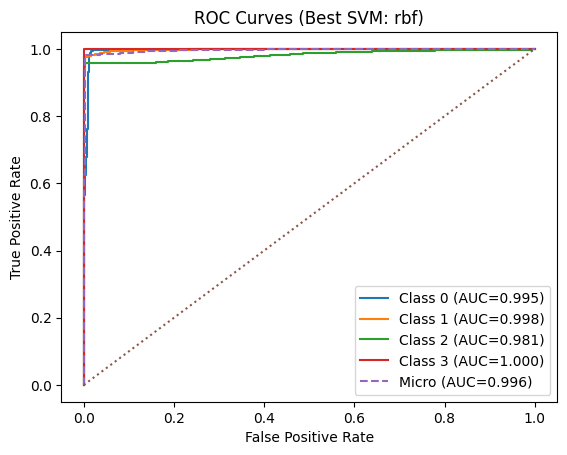

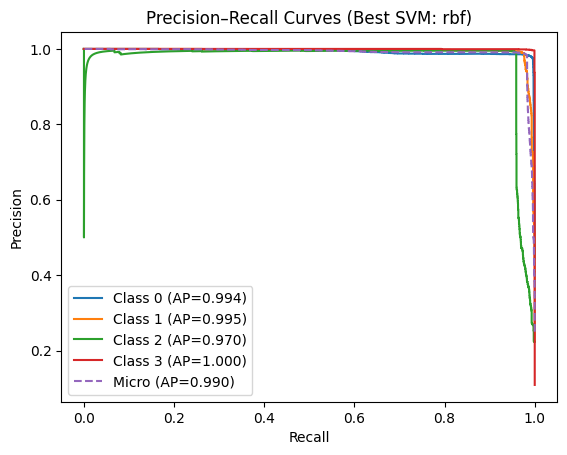


=== TPR at fixed FPR (on TEST) ===
  FPR=1%:  |  class 0 TPR=0.9140  |  class 1 TPR=0.9778  |  class 2 TPR=0.9590  |  class 3 TPR=1.0000  |  micro TPR=0.9830
  FPR=5%:  |  class 0 TPR=0.9969  |  class 1 TPR=0.9904  |  class 2 TPR=0.9590  |  class 3 TPR=1.0000  |  micro TPR=0.9839


In [13]:
# ---------------- Curves & TPR@FPR ----------------

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve


scores = best_model.decision_function(X_test)
Y_test_bin = label_binarize(y_test, classes=classes)  # shape (n_samples, n_classes)

# ROC per class + micro
fpr = dict(); tpr = dict(); roc_auc = dict()
for i, c in enumerate(classes):
    fpr[c], tpr[c], _ = roc_curve(Y_test_bin[:, i], scores[:, i])
    roc_auc[c] = auc(fpr[c], tpr[c])

# micro-average (stack all)
fpr["micro"], tpr["micro"], _ = roc_curve(Y_test_bin.ravel(), scores.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Plot ROC
plt.figure()
for c in classes:
    plt.plot(fpr[c], tpr[c], label=f"Class {c} (AUC={roc_auc[c]:.3f})")
plt.plot(fpr["micro"], tpr["micro"], linestyle="--", label=f"Micro (AUC={roc_auc['micro']:.3f})")
plt.plot([0,1], [0,1], linestyle=":")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curves (Best SVM: {best_kernel})")
plt.legend()
plt.show()

# Precision-Recall per class + micro
prec = dict(); rec = dict(); ap = dict()
for i, c in enumerate(classes):
    prec[c], rec[c], _ = precision_recall_curve(Y_test_bin[:, i], scores[:, i])
    ap[c] = average_precision_score(Y_test_bin[:, i], scores[:, i])

prec["micro"], rec["micro"], _ = precision_recall_curve(Y_test_bin.ravel(), scores.ravel())
ap["micro"] = average_precision_score(Y_test_bin, scores, average="micro")

# Plot PR
plt.figure()
for c in classes:
    plt.plot(rec[c], prec[c], label=f"Class {c} (AP={ap[c]:.3f})")
plt.plot(rec["micro"], prec["micro"], linestyle="--", label=f"Micro (AP={ap['micro']:.3f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall Curves (Best SVM: {best_kernel})")
plt.legend()
plt.show()

# TPR at fixed FPR (1% and 5%) per class + micro
def tpr_at_fixed_fpr(fpr_arr, tpr_arr, target_fpr):
    # interpolate TPR at exact target FPR (cap within [0,1])
    target = float(target_fpr)
    target = max(0.0, min(1.0, target))
    return float(np.interp(target, fpr_arr, tpr_arr))

targets = [0.01, 0.05]
print("\n=== TPR at fixed FPR (on TEST) ===")
for tg in targets:
    line = [f"FPR={int(tg*100)}%:"]
    for c in classes:
        line.append(f"class {c} TPR={tpr_at_fixed_fpr(fpr[c], tpr[c], tg):.4f}")
    # ✅ fixed: single colon before .4f
    line.append(f"micro TPR={tpr_at_fixed_fpr(fpr['micro'], tpr['micro'], tg):.4f}")
    print("  " + "  |  ".join(line))

In [14]:
# ---------------- Save best model ----------------
import joblib
from datetime import datetime
import os

# Ensure directory exists
save_dir = "best_model_trained_after_parameter_tuning"
os.makedirs(save_dir, exist_ok=True)

# Create filename with timestamp
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
save_path = os.path.join(save_dir, f"best_svm_model_with_f1macro{timestamp}.pkl")

# Dump the pipeline (scaler + SVM) as .pkl
joblib.dump(best_model, save_path)

print(f"\n[MODEL SAVED] Best SVM model stored at:\n  {save_path}")



[MODEL SAVED] Best SVM model stored at:
  best_model_trained_after_parameter_tuning/best_svm_model_with_f1macro20251014_180733.pkl
